<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/models/newDense.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


In [54]:
!ls {path}

auto_test  test  train	val


In [55]:
from torchvision import transforms, datasets

base = path

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)


train: 5778 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


In [56]:
# only testing
img, label = train[0]
img, label

(tensor([[[-0.5938, -0.5596, -0.5253,  ..., -0.6623, -0.7308, -0.8164],
          [-0.5938, -0.5596, -0.5596,  ..., -0.6794, -0.7650, -0.8507],
          [-0.5767, -0.5767, -0.5424,  ..., -0.6965, -0.7650, -0.8164],
          ...,
          [-1.5014, -1.5014, -1.4672,  ..., -0.7822, -0.7650, -0.7650],
          [-1.5014, -1.5185, -1.4672,  ..., -0.7308, -0.7479, -0.7479],
          [-1.5014, -1.5014, -1.4843,  ..., -0.7137, -0.7137, -0.7479]],
 
         [[-0.4776, -0.4426, -0.4076,  ..., -0.5476, -0.6176, -0.7052],
          [-0.4776, -0.4426, -0.4426,  ..., -0.5651, -0.6527, -0.7402],
          [-0.4601, -0.4601, -0.4251,  ..., -0.5826, -0.6527, -0.7052],
          ...,
          [-1.4055, -1.4055, -1.3704,  ..., -0.6702, -0.6527, -0.6527],
          [-1.4055, -1.4230, -1.3704,  ..., -0.6176, -0.6352, -0.6352],
          [-1.4055, -1.4055, -1.3880,  ..., -0.6001, -0.6001, -0.6352]],
 
         [[-0.2532, -0.2184, -0.1835,  ..., -0.3230, -0.3927, -0.4798],
          [-0.2532, -0.2184,

In [57]:
# validation
class_to_i = train.class_to_idx
class_to_i

{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}

In [58]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})

train {'0': 2286, '1': 1046, '2': 1516, '3': 757, '4': 173}
val {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}
test {'0': 639, '1': 296, '2': 447, '3': 223, '4': 51}


In [59]:
splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds.targets) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds.targets)
    split_pct = (split_size / total_samples) * 100

    counts = Counter(ds.targets)
    # calculate class percentages within the split
    class_dist = {ds.classes[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}

    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 5778 (69.95%) | Classes: {'0': '2286 (39.6%)', '1': '1046 (18.1%)', '2': '1516 (26.2%)', '3': '757 (13.1%)', '4': '173 (3.0%)'}
val   | Total:  826 (10.00%) | Classes: {'0': '328 (39.7%)', '1': '153 (18.5%)', '2': '212 (25.7%)', '3': '106 (12.8%)', '4': '27 (3.3%)'}
test  | Total: 1656 (20.05%) | Classes: {'0': '639 (38.6%)', '1': '296 (17.9%)', '2': '447 (27.0%)', '3': '223 (13.5%)', '4': '51 (3.1%)'}


In [60]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (5 * counts[i]) for i in range(5)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


In [61]:
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
print("train:", len(train))


train: 5778


In [62]:
from torch.utils.data import DataLoader

val = datasets.ImageFolder(f"{base}/val", transform=tf)
test = datasets.ImageFolder(f"{base}/test", transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val, batch_size=32, shuffle=False, num_workers=4)
test_loader = DataLoader(test, batch_size=32, shuffle=False, num_workers=4)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])


batch shape: torch.Size([32, 3, 224, 224])
labels: tensor([1, 0, 2, 0, 0, 3, 0, 0, 3, 2])


In [63]:
import cv2
import numpy as np
from PIL import Image

# 1) دالة التنظيف: noise reduction + تحسين التباين
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                      # رمادي
        g = cv2.GaussianBlur(g, (3, 3), 0)                  # إزالة الضوضاء
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train (مع augmentation)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 4) نعيد تحميل الداتا بالـ pipeline الجديد
train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True, num_workers=4)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False, num_workers=4)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False, num_workers=4)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


batch shape: torch.Size([32, 3, 224, 224])
train: 5778 | val: 826 | test: 1656


### Why does the image have 3 channels instead of 1?

Even though your knee X-ray dataset is grayscale, your image tensor shape shows `3` channels because of this line in your pre-processing transforms:

```python
transforms.Grayscale(3)
```

* **Channel Duplication:** This transform takes the single-channel grayscale image and replicates it across 3 identical channels ($R = G = B$).
* **Pre-trained Model Compatibility:** Transfer learning backbones (such as ResNet, EfficientNet, etc.) are pre-trained on ImageNet (RGB datasets) and strictly require a 3-channel input shape. Replicating the channels allows you to use these models without needing to modify their first convolutional layer.

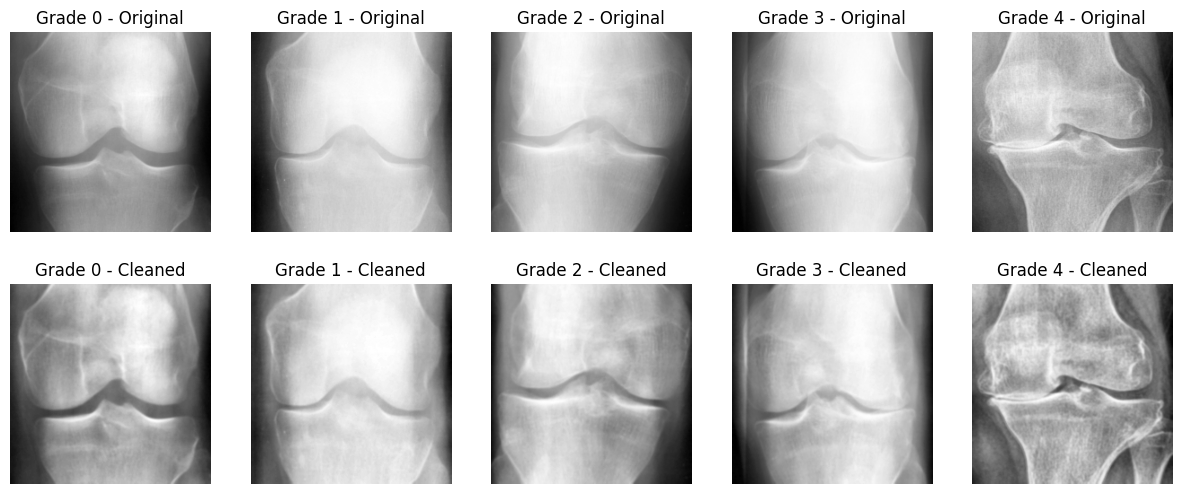

In [64]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(cleaned, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cleaned"); axes[1][k].axis("off")
plt.show()

# مو مهم بس عشان اشوف الصور قبل وبعد

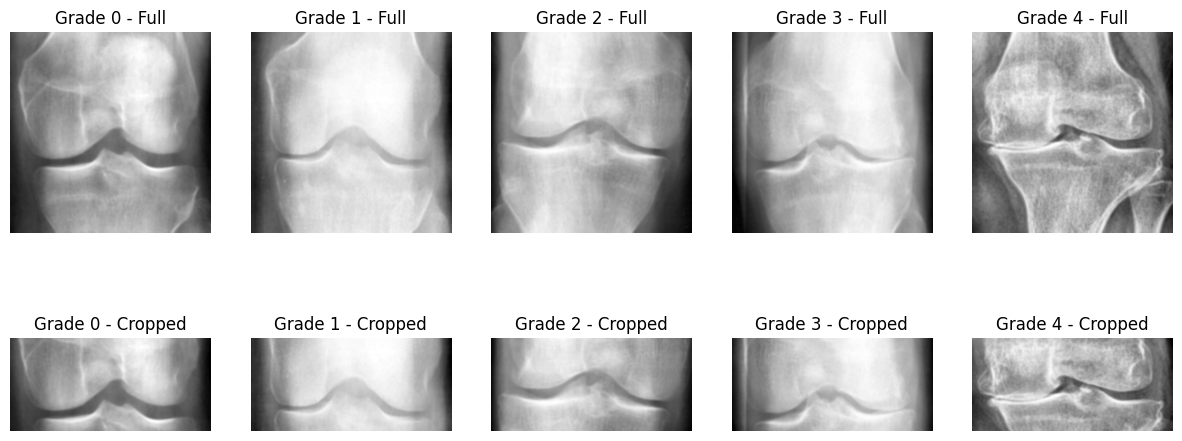

In [65]:
import matplotlib.pyplot as plt
from PIL import Image

def crop_center(img, top=60, bottom=60):
    img = img.resize((224, 224))
    return img.crop((0, top, 224, 224 - bottom))   # 224 x 104

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    p = train.samples[train.targets.index(k)][0]
    original = Denoise()(Image.open(p).convert("L")).resize((224, 224))
    cropped = crop_center(Denoise()(Image.open(p).convert("L")))
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Full"); axes[0][k].axis("off")
    axes[1][k].imshow(cropped, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cropped"); axes[1][k].axis("off")
plt.show()


# Agnostic Code

In [66]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Training the model (DenseNet-201)

## Training

In [67]:
def train_step(model,
               data_loader,
               loss_fn,
               optm,
               acc_fn,
               scheduler = None,
               device = device):

  train_loss, train_acc = 0.0, 0.0

  model.to(device)

  model.train() # set model to training mode

  # itera through data/ batches
  for input, label in data_loader:
    input, label = input.to(device), label.to(device)

    # 1. forward
    output = model(input)

    # 2. calculate the loss
    loss = loss_fn(output, label)
    train_loss += loss.item() * input.size(0)
    train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    # 3. optimizer zero grad
    optm.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optm.step() # to change the weights

    # 6. scheduler step
    if scheduler is not None:
      scheduler.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}')

In [68]:
import torch.backends.cudnn as cudnn
cudnn.benchmark = True   # hey GPU find the most optimized way to run

In [69]:
from sklearn.metrics import f1_score

def val_macro_f1():
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in val_loader:
            preds.extend(model(x.to(device)).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    return f1_score(labels, preds, average="macro")

In [70]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions.

    Args:
        y_true (torch.Tensor): Truth labels for predictions.
        y_pred (torch.Tensor): Predictions to be compared to predictions.

    Returns:
        [torch.float]: Accuracy value between y_true and y_pred, e.g. 78.45
    """
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [71]:
def run_epoch(loader, optimizer=None, freeze_backbone=False):
    """Train one epoch if optimizer is given, otherwise just evaluate."""
    training = optimizer is not None
    model.train(training)
    if training and freeze_backbone:
        model.features.eval()              # keep frozen part fully fixed (like Keras)

    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, 100 * correct / n

In [72]:
def test_report():
    te_loss, te_acc = run_epoch(test_loader)
    print(f"TEST loss {te_loss:.3f} | TEST acc {te_acc:.2f}%")
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in test_loader:
            preds.extend(model(x.to(device)).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    print(classification_report(labels, preds, zero_division=0))
    print(confusion_matrix(labels, preds))

In [73]:
import copy

def fit(optimizer, epochs, freeze_backbone, name):
    best_score, best_state = 0, None

    for e in range(epochs):
        tr_loss, tr_acc = run_epoch(train_loader, optimizer, freeze_backbone)
        va_loss, va_acc = run_epoch(val_loader)

        f1 = val_macro_f1()
        if f1 > best_score:
          best_score, best_state = f1, copy.deepcopy(model.state_dict())

        print(f"[{name}] Epoch {e+1:02d}/{epochs} | "
              f"train loss {tr_loss:.3f} acc {tr_acc:.1f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.1f} | "
              f"val F1 {f1:.3f}")

    model.load_state_dict(best_state)
    print(f"Restored best epoch (val F1 {best_score:.3f})")

## PHASE 1 -- freeze DenseNet, train only the new layer, 10 epochs

In [74]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load the pre-trained DenseNet model
model = models.densenet201(weights=models.DenseNet201_Weights.DEFAULT)

# 2. Freeze all backbone parameters first
for param in model.parameters():
    param.requires_grad = False

# 3. Replace the classifier. Newly created layers have requires_grad=True by default.
num_ftrs = model.classifier.in_features
model.classifier = nn.Linear(num_ftrs, 5)
model = model.to(device)

# 4. Setup loss function and optimizer
# Pass only the classifier parameters to the optimizer for Phase 1
loss_fn = nn.CrossEntropyLoss(weight=class_weights.float().to(device))
optm = optim.Adam(model.classifier.parameters(), lr=0.001)

acc_fn = accuracy_fn

# Run training Phase 1
fit(optm, epochs=10, freeze_backbone=True, name="Phase 1: frozen")

print("\n--- Test result after Phase 1 ---")
test_report()

[Phase 1: frozen] Epoch 01/10 | train loss 1.526 acc 30.1 | val loss 1.320 acc 45.9 | val F1 0.323
[Phase 1: frozen] Epoch 02/10 | train loss 1.377 acc 36.9 | val loss 1.314 acc 45.0 | val F1 0.287
[Phase 1: frozen] Epoch 03/10 | train loss 1.322 acc 38.5 | val loss 1.254 acc 48.1 | val F1 0.387
[Phase 1: frozen] Epoch 04/10 | train loss 1.277 acc 40.6 | val loss 1.222 acc 49.0 | val F1 0.376
[Phase 1: frozen] Epoch 05/10 | train loss 1.264 acc 41.5 | val loss 1.248 acc 43.2 | val F1 0.399
[Phase 1: frozen] Epoch 06/10 | train loss 1.240 acc 41.3 | val loss 1.206 acc 49.8 | val F1 0.381
[Phase 1: frozen] Epoch 07/10 | train loss 1.217 acc 43.2 | val loss 1.275 acc 51.1 | val F1 0.364
[Phase 1: frozen] Epoch 08/10 | train loss 1.212 acc 43.0 | val loss 1.300 acc 46.7 | val F1 0.363
[Phase 1: frozen] Epoch 09/10 | train loss 1.204 acc 43.5 | val loss 1.234 acc 47.9 | val F1 0.375
[Phase 1: frozen] Epoch 10/10 | train loss 1.203 acc 42.9 | val loss 1.242 acc 46.1 | val F1 0.430
Restored b

## PHASE 2 -- unfreeze everything, fine-tune, lr 0.001, 20 more epochs

In [75]:
for p in model.parameters():
    p.requires_grad = True

# NEW optimizer covering the whole network (the Phase 1 one only had the classifier)
optm = optim.Adam(model.parameters(), lr=0.0001)

fit(optm, epochs=20, freeze_backbone=False, name="Phase 2: fine-tune")

print("\n--- Final test result after fine-tuning ---")
test_report()

[Phase 2: fine-tune] Epoch 01/20 | train loss 1.223 acc 44.2 | val loss 1.193 acc 48.1 | val F1 0.506
[Phase 2: fine-tune] Epoch 02/20 | train loss 0.937 acc 53.7 | val loss 1.095 acc 54.5 | val F1 0.478
[Phase 2: fine-tune] Epoch 03/20 | train loss 0.828 acc 57.1 | val loss 1.005 acc 51.8 | val F1 0.573
[Phase 2: fine-tune] Epoch 04/20 | train loss 0.775 acc 60.0 | val loss 0.919 acc 59.7 | val F1 0.609
[Phase 2: fine-tune] Epoch 05/20 | train loss 0.754 acc 61.6 | val loss 0.871 acc 60.2 | val F1 0.650
[Phase 2: fine-tune] Epoch 06/20 | train loss 0.719 acc 63.5 | val loss 0.947 acc 58.1 | val F1 0.614
[Phase 2: fine-tune] Epoch 07/20 | train loss 0.685 acc 64.2 | val loss 0.924 acc 59.1 | val F1 0.625
[Phase 2: fine-tune] Epoch 08/20 | train loss 0.657 acc 66.3 | val loss 0.947 acc 60.7 | val F1 0.611
[Phase 2: fine-tune] Epoch 09/20 | train loss 0.641 acc 67.6 | val loss 0.964 acc 52.9 | val F1 0.630
[Phase 2: fine-tune] Epoch 10/20 | train loss 0.583 acc 69.6 | val loss 1.044 acc 

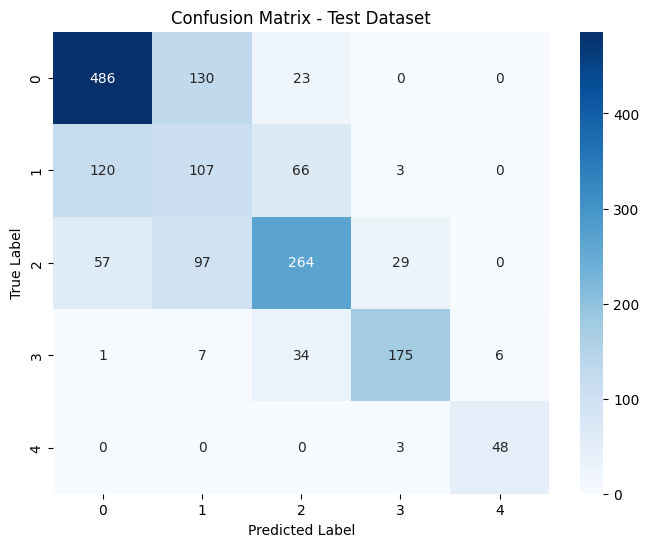

In [76]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Put model in evaluation mode
model.eval()
all_preds = []
all_labels = []

# Get predictions on test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)
class_names = train.classes

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Dataset')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [77]:
from sklearn.metrics import cohen_kappa_score
import torch

# Put model in evaluation mode
model.eval()
all_preds = []
all_labels = []

# Get predictions on the test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Calculate Quadratic Weighted Kappa (QWK)
qwk = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
print(f"Quadratic Weighted Kappa (QWK): {qwk:.4f}")

Quadratic Weighted Kappa (QWK): 0.8169
